# Passing networks: Bayer Leverkusen 2023/24

A walkthrough of the analysis behind the README. All data logic is SQL (`sql/`) run on DuckDB;
graph metrics use networkx (`src/network.py`); `src/plots.py` only draws.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, Markdown, display
from src.queries import PassAnalysis
from src.network import centrality, centralisation
from src import plots

pd.set_option("display.precision", 2)
db = PassAnalysis()          # connects and creates the minutes / pass-features / first-sub views
TEAM = "Bayer Leverkusen"

def show_sql(name):
    display(Markdown(f"**`sql/{name}.sql`**\n```sql\n{db.sql(name).strip()}\n```"))

## 1. The data

In [2]:
db.con.sql("""SELECT 'matches' t, count(*) n FROM matches UNION ALL SELECT 'passes', count(*) FROM passes
   UNION ALL SELECT 'appearances', count(*) FROM appearances UNION ALL SELECT 'shots', count(*) FROM shots""").df()

,t,n
0,matches,34
1,passes,39214
2,appearances,1554
3,shots,916


### Minutes played (and a sanity check)

StatsBomb's clock restarts at 45:00 after half-time, so second-half times are converted to elapsed time.

In [3]:
show_sql("01_minutes_played")

**`sql/01_minutes_played.sql`**
```sql
-- Minutes played per player per match.
-- On  = kick-off for starters, otherwise the time they came on as a substitute.
-- Off = the time they were substituted or sent off, otherwise the final whistle.
-- Position changes ("Tactical Shift") and temporary treatment ("Player Off/On") are ignored.
-- StatsBomb's clock restarts at 45:00 for the second half, so second-half times are
-- converted to elapsed match time: end of first half + (clock - 45:00).
CREATE OR REPLACE TEMP VIEW minutes_played AS
WITH events AS (
    SELECT
        a.*,
        c.h1_end,
        c.h1_end + (c.h2_end - 45 * 60) AS match_end,
        CASE WHEN a.from_period = 1 THEN a.from_clock
             ELSE c.h1_end + (a.from_clock - 45 * 60) END AS from_elapsed,
        CASE WHEN a.to_period = 1 THEN a.to_clock
             WHEN a.to_period = 2 THEN c.h1_end + (a.to_clock - 45 * 60) END AS to_elapsed
    FROM appearances AS a
    JOIN clock AS c USING (match_id)
),
per_player AS (
    SELECT
        match_id, team, player,
        any_value(jersey_number) AS jersey_number,
        arg_min(position, from_elapsed) AS main_position,
        bool_or(start_reason = 'Starting XI') AS started,
        min(CASE WHEN start_reason = 'Starting XI' THEN 0
                 WHEN start_reason LIKE 'Substitution - On%' THEN from_elapsed END) AS on_s,
        min(CASE WHEN end_reason LIKE 'Substitution - Off%'
                   OR end_reason LIKE 'Foul Committed%' THEN to_elapsed END) AS off_s,
        any_value(match_end) AS match_end
    FROM events
    GROUP BY match_id, team, player
)
SELECT
    match_id, team, player, jersey_number, main_position, started,
    round((coalesce(off_s, match_end) - on_s) / 60.0, 1) AS minutes
FROM per_player
WHERE on_s IS NOT NULL;
```

In [4]:
check = db.con.sql("""
    SELECT m.match_id, m.team, sum(minutes) AS total_minutes,
           any_value(c.h1_end + c.h2_end - 2700) / 60.0 AS match_minutes
    FROM minutes_played m JOIN clock c USING (match_id) GROUP BY 1, 2""").df()
check["players_on_pitch"] = check["total_minutes"] / check["match_minutes"]
check["players_on_pitch"].describe()

count    68.00
mean     10.94
std       0.19
min      10.12
25%      11.00
50%      11.00
75%      11.00
max      11.01
Name: players_on_pitch, dtype: float64

Every team totals about 11 × the match length. The few below 11 are matches with a red card.

## 2. Season network and the hub

In [5]:
show_sql("06_season_nodes")
nodes = db.run("06_season_nodes", team=TEAM, min_minutes=1800)
edges = db.run("07_season_edges", team=TEAM)
nodes[["player", "minutes", "passes_made_p90", "progressive_p90", "involvement_pct"]]

**`sql/06_season_nodes.sql`**
```sql
-- Season passing profile for every player with at least $min_minutes minutes.
-- Node position = average location of completed open-play passes made and received.
WITH team_passes AS (
    SELECT * FROM pass_features
    WHERE team = $team AND is_complete AND is_open_play
),
touches AS (
    SELECT player,    x,     y,     1 AS made, 0 AS received, is_progressive AS prog FROM team_passes
    UNION ALL
    SELECT recipient, end_x, end_y, 0, 1, false FROM team_passes WHERE recipient IS NOT NULL
),
minutes AS (
    SELECT player,
           sum(minutes) AS minutes,
           mode(main_position) AS usual_position,
           mode(jersey_number) AS jersey_number
    FROM minutes_played WHERE team = $team
    GROUP BY player
),
team_total AS (SELECT count(*) AS n FROM team_passes)
SELECT
    t.player,
    m.jersey_number,
    m.usual_position,
    round(m.minutes)                                        AS minutes,
    avg(t.x)                                                AS x,
    avg(t.y)                                                AS y,
    sum(t.made)                                             AS passes_made,
    sum(t.received)                                         AS passes_received,
    sum(t.made)     * 90.0 / m.minutes                      AS passes_made_p90,
    sum(t.prog::INT) * 90.0 / m.minutes                     AS progressive_p90,
    -- share of all the team's completed open-play passes this player made or received
    100.0 * (sum(t.made) + sum(t.received)) / any_value(tt.n) AS involvement_pct
FROM touches AS t
JOIN minutes AS m USING (player)
CROSS JOIN team_total AS tt
WHERE m.minutes >= $min_minutes
GROUP BY t.player, m.jersey_number, m.usual_position, m.minutes
ORDER BY involvement_pct DESC;
```

,player,minutes,passes_made_p90,progressive_p90,involvement_pct
0,Granit Xhaka,3035.0,88.25,5.34,28.91
1,Jonathan Tah,2848.0,64.11,2.53,18.39
2,Exequiel Alejandro Palacios,1897.0,86.32,5.22,17.49
3,Edmond Fayçal Tapsoba,2263.0,68.17,4.77,15.98
4,Florian Wirtz,2529.0,52.70,7.29,15.90
5,Alejandro Grimaldo García,2995.0,45.44,4.39,15.64
6,Robert Andrich,1849.0,64.26,3.31,12.36
7,Jonas Hofmann,2335.0,43.90,3.66,11.97
8,Odilon Kossonou,1956.0,55.44,3.31,11.48
9,Jeremie Frimpong,2379.0,27.24,2.80,8.38


In [6]:
cent = centrality(nodes, edges)
cent

,player,weighted_degree_pct,betweenness,pagerank
0,Granit Xhaka,17.76,0.53,0.17
1,Exequiel Alejandro Palacios,11.56,0.00,0.11
2,Jonathan Tah,11.29,0.04,0.11
3,Edmond Fayçal Tapsoba,10.68,0.16,0.10
4,Florian Wirtz,9.42,0.00,0.09
5,Odilon Kossonou,8.10,0.02,0.08
6,Alejandro Grimaldo García,8.33,0.00,0.08
7,Jonas Hofmann,7.69,0.00,0.08
8,Robert Andrich,6.96,0.00,0.07
9,Jeremie Frimpong,5.26,0.00,0.06


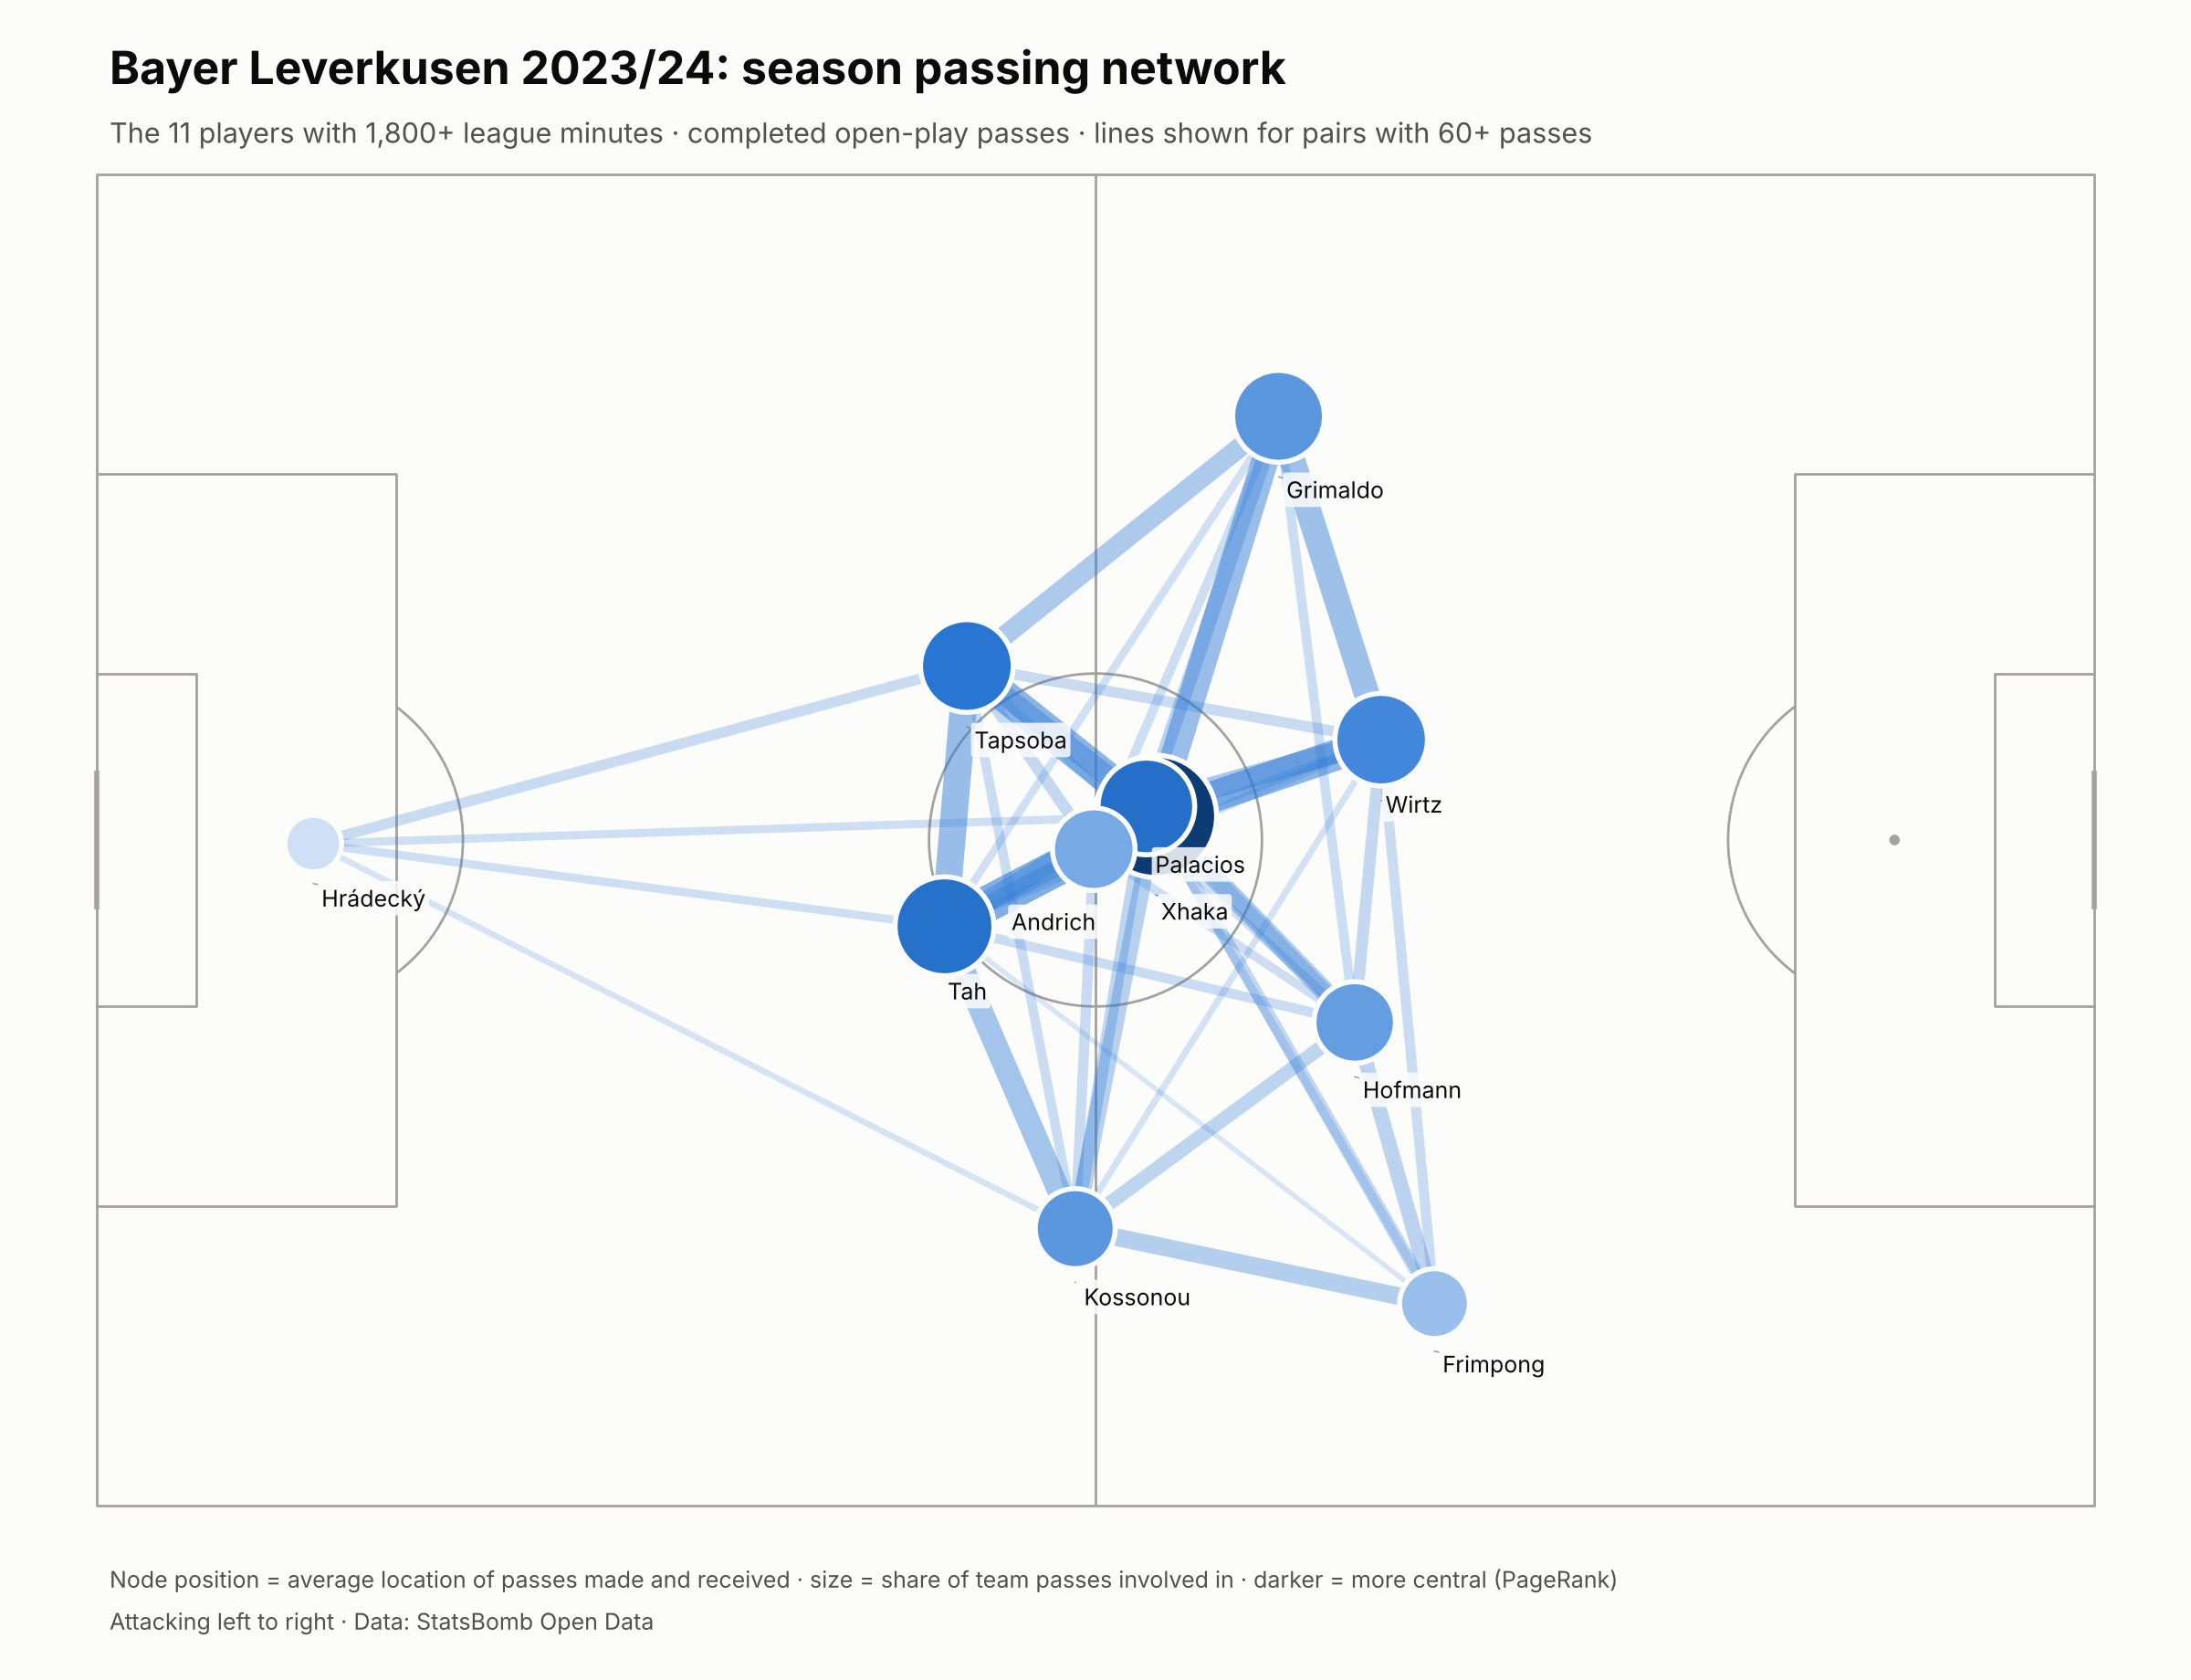

In [7]:
plots.season_network(nodes, edges, cent, "../figures/season_network.png")
Image("../figures/season_network.png", width=800)

Xhaka is involved in 28.9% of every completed open-play pass. His betweenness of 0.53 means he sits
on the strongest route between more than half of all pairs of teammates.

## 3. Pass share across the season

In [8]:
show_sql("08_match_summary")
summary = db.run("08_match_summary")
lev = summary[summary["team"] == TEAM]
lev.nsmallest(6, "pass_share_pct")[["match_date", "opponent", "venue", "pass_share_pct", "goals", "goals_against", "xg"]]

**`sql/08_match_summary.sql`**
```sql
-- Team passing and outcome summary for every match (both teams).
WITH passing AS (
    SELECT
        match_id, team,
        count(*)                                               AS passes,
        count(*) FILTER (WHERE is_complete)                    AS completed,
        100.0 * avg(is_complete::INT)                          AS completion_pct,
        count(*) FILTER (WHERE is_complete AND is_progressive) AS progressive,
        -- share of completed passes made in the attacking half: a simple territory measure
        100.0 * avg((x >= 60)::INT) FILTER (WHERE is_complete) AS own_passes_in_opp_half_pct
    FROM pass_features
    GROUP BY match_id, team
),
shooting AS (
    SELECT match_id, team, sum(xg) AS xg FROM shots GROUP BY match_id, team
)
SELECT
    m.match_date,
    p.match_id,
    p.team,
    CASE WHEN p.team = m.home_team THEN m.away_team ELSE m.home_team END AS opponent,
    CASE WHEN p.team = m.home_team THEN 'H' ELSE 'A' END                AS venue,
    p.passes, p.completed, p.completion_pct, p.progressive, p.own_passes_in_opp_half_pct,
    -- possession proxy: share of the match's completed passes
    100.0 * p.completed / sum(p.completed) OVER (PARTITION BY p.match_id) AS pass_share_pct,
    -- goals from the official score (shots miss own goals)
    CASE WHEN p.team = m.home_team THEN m.home_score ELSE m.away_score END AS goals,
    CASE WHEN p.team = m.home_team THEN m.away_score ELSE m.home_score END AS goals_against,
    coalesce(s.xg, 0) AS xg
FROM passing AS p
JOIN matches AS m USING (match_id)
LEFT JOIN shooting AS s USING (match_id, team)
ORDER BY m.match_date, p.team;
```

,match_date,opponent,venue,pass_share_pct,goals,goals_against,xg
40,2024-02-10,Bayern Munich,H,37.69,3,0,1.03
0,2023-08-19,RB Leipzig,H,43.61,3,2,1.52
62,2024-05-05,Eintracht Frankfurt,A,43.93,5,1,2.59
26,2023-12-10,VfB Stuttgart,A,47.51,1,1,1.53
60,2024-04-27,VfB Stuttgart,H,48.41,2,2,1.65
6,2023-09-15,Bayern Munich,A,48.92,2,2,2.22


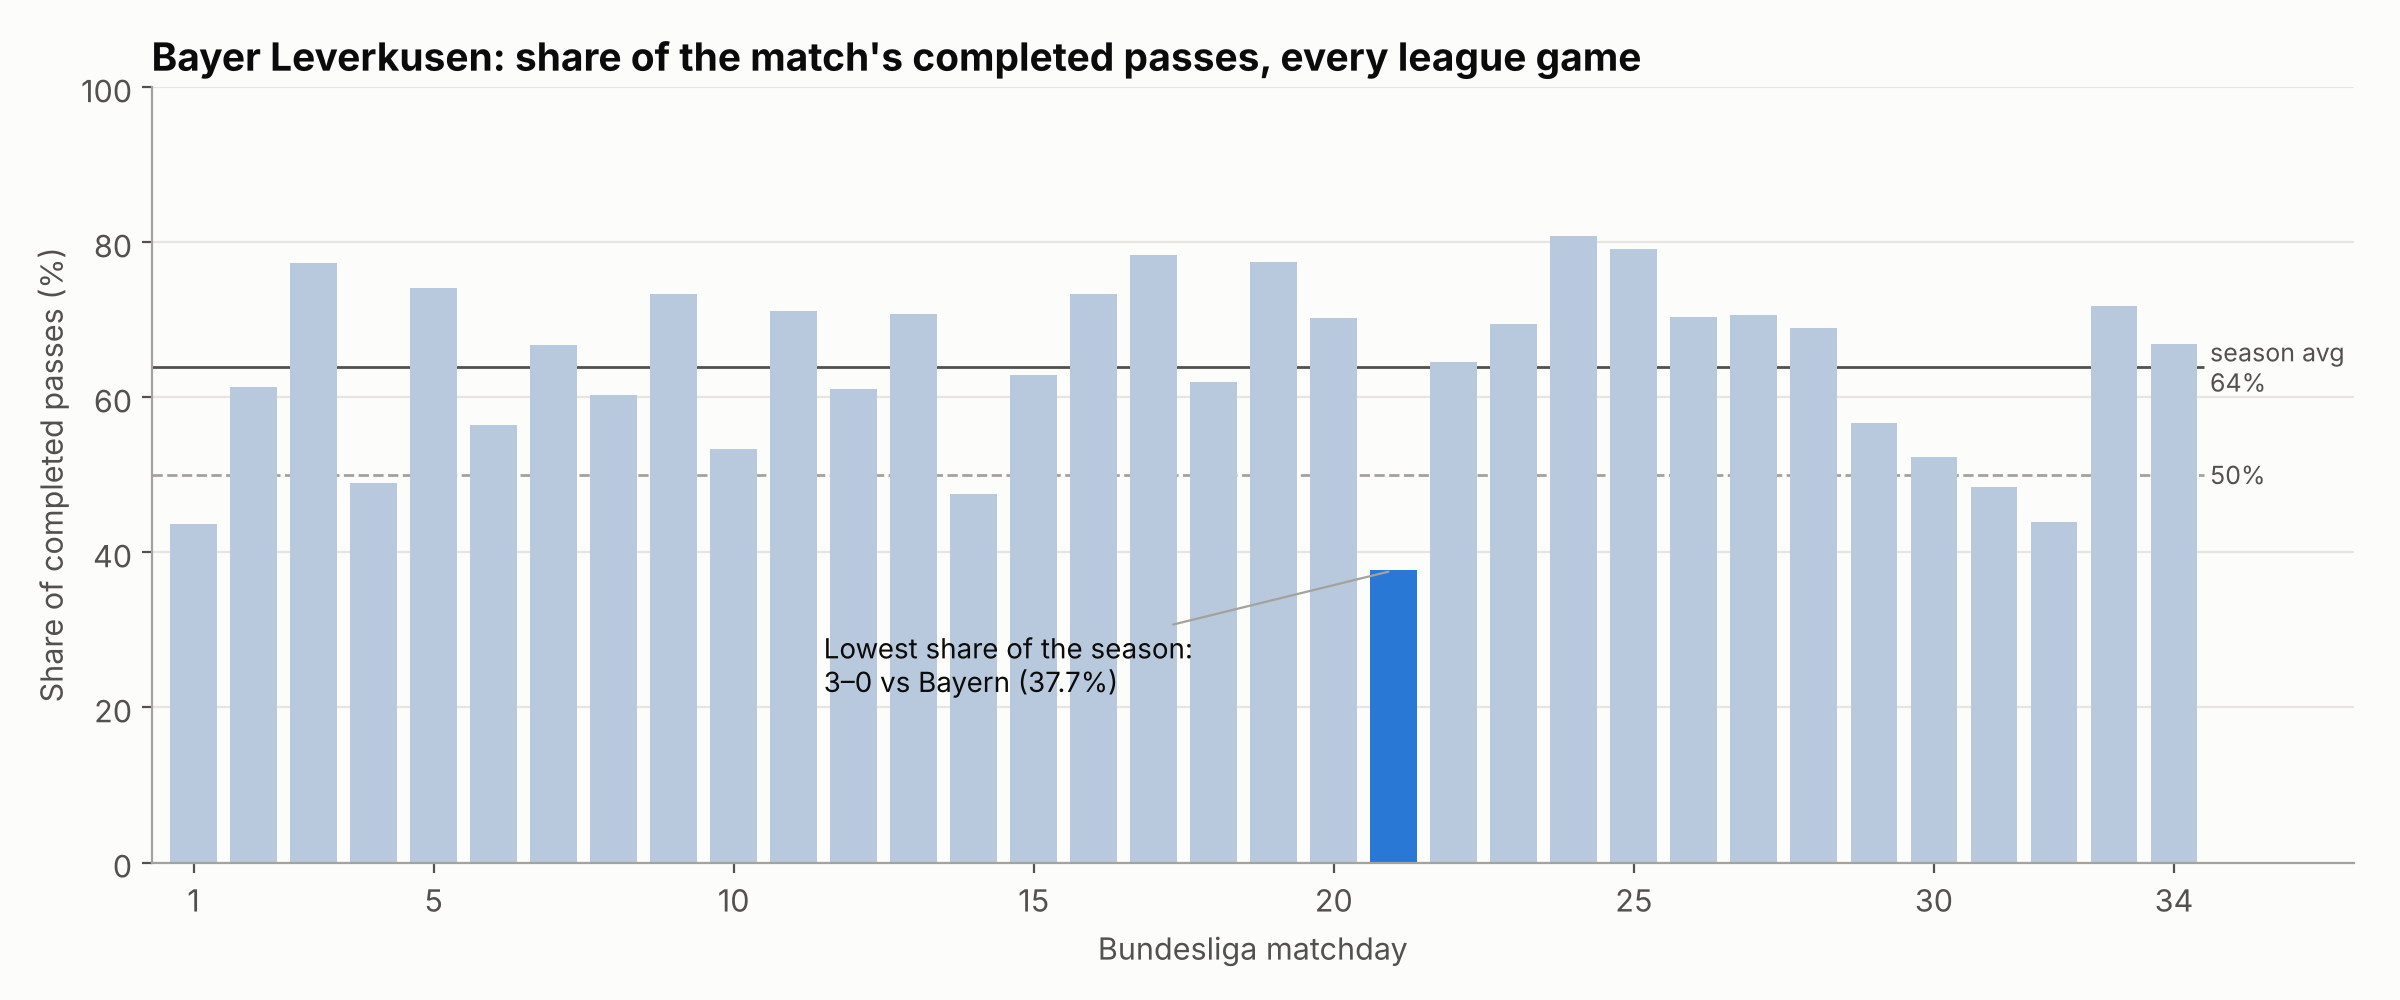

In [9]:
Image("../figures/pass_share_by_match.png", width=800)

## 4. Leverkusen 3–0 Bayern: a match network

Networks stop at the team's first substitution, so the same 11 players are on the pitch throughout.

In [10]:
show_sql("05_match_edges")
feb = db.match_id(TEAM, "Bayern Munich", "2024-02-10")
for team in [TEAM, "Bayern Munich"]:
    n = db.run("04_match_nodes", match_id=feb, team=team, full_match=False)
    e = db.run("05_match_edges", match_id=feb, team=team, full_match=False)
    print(f"{team}: {e['passes'].sum()} passes, centralisation {centralisation(n, e):.2f}, "
          f"most central: {', '.join(centrality(n, e)['player'].head(3))}")

**`sql/05_match_edges.sql`**
```sql
-- Passing-network edges: completed open-play passes between each pair of players,
-- both directions combined (up to the team's first substitution by default).
SELECT
    least(f.player, f.recipient)    AS player_a,
    greatest(f.player, f.recipient) AS player_b,
    count(*)                        AS passes
FROM pass_features AS f
LEFT JOIN first_change AS fc USING (match_id, team)
WHERE f.match_id = $match_id AND f.team = $team
  AND f.is_complete AND f.is_open_play
  -- $full_match = true uses the whole match; otherwise stop at the first substitution
      AND ($full_match OR f.elapsed < coalesce(fc.cutoff_elapsed, 1e9))
  AND f.recipient IS NOT NULL
GROUP BY player_a, player_b
ORDER BY passes DESC;
```

Bayer Leverkusen: 279 passes, centralisation 0.11, most central: Granit Xhaka, Edmond Fayçal Tapsoba, Florian Wirtz
Bayern Munich: 364 passes, centralisation 0.21, most central: Eric Dier, Dayotchanculle Upamecano, Leon Goretzka


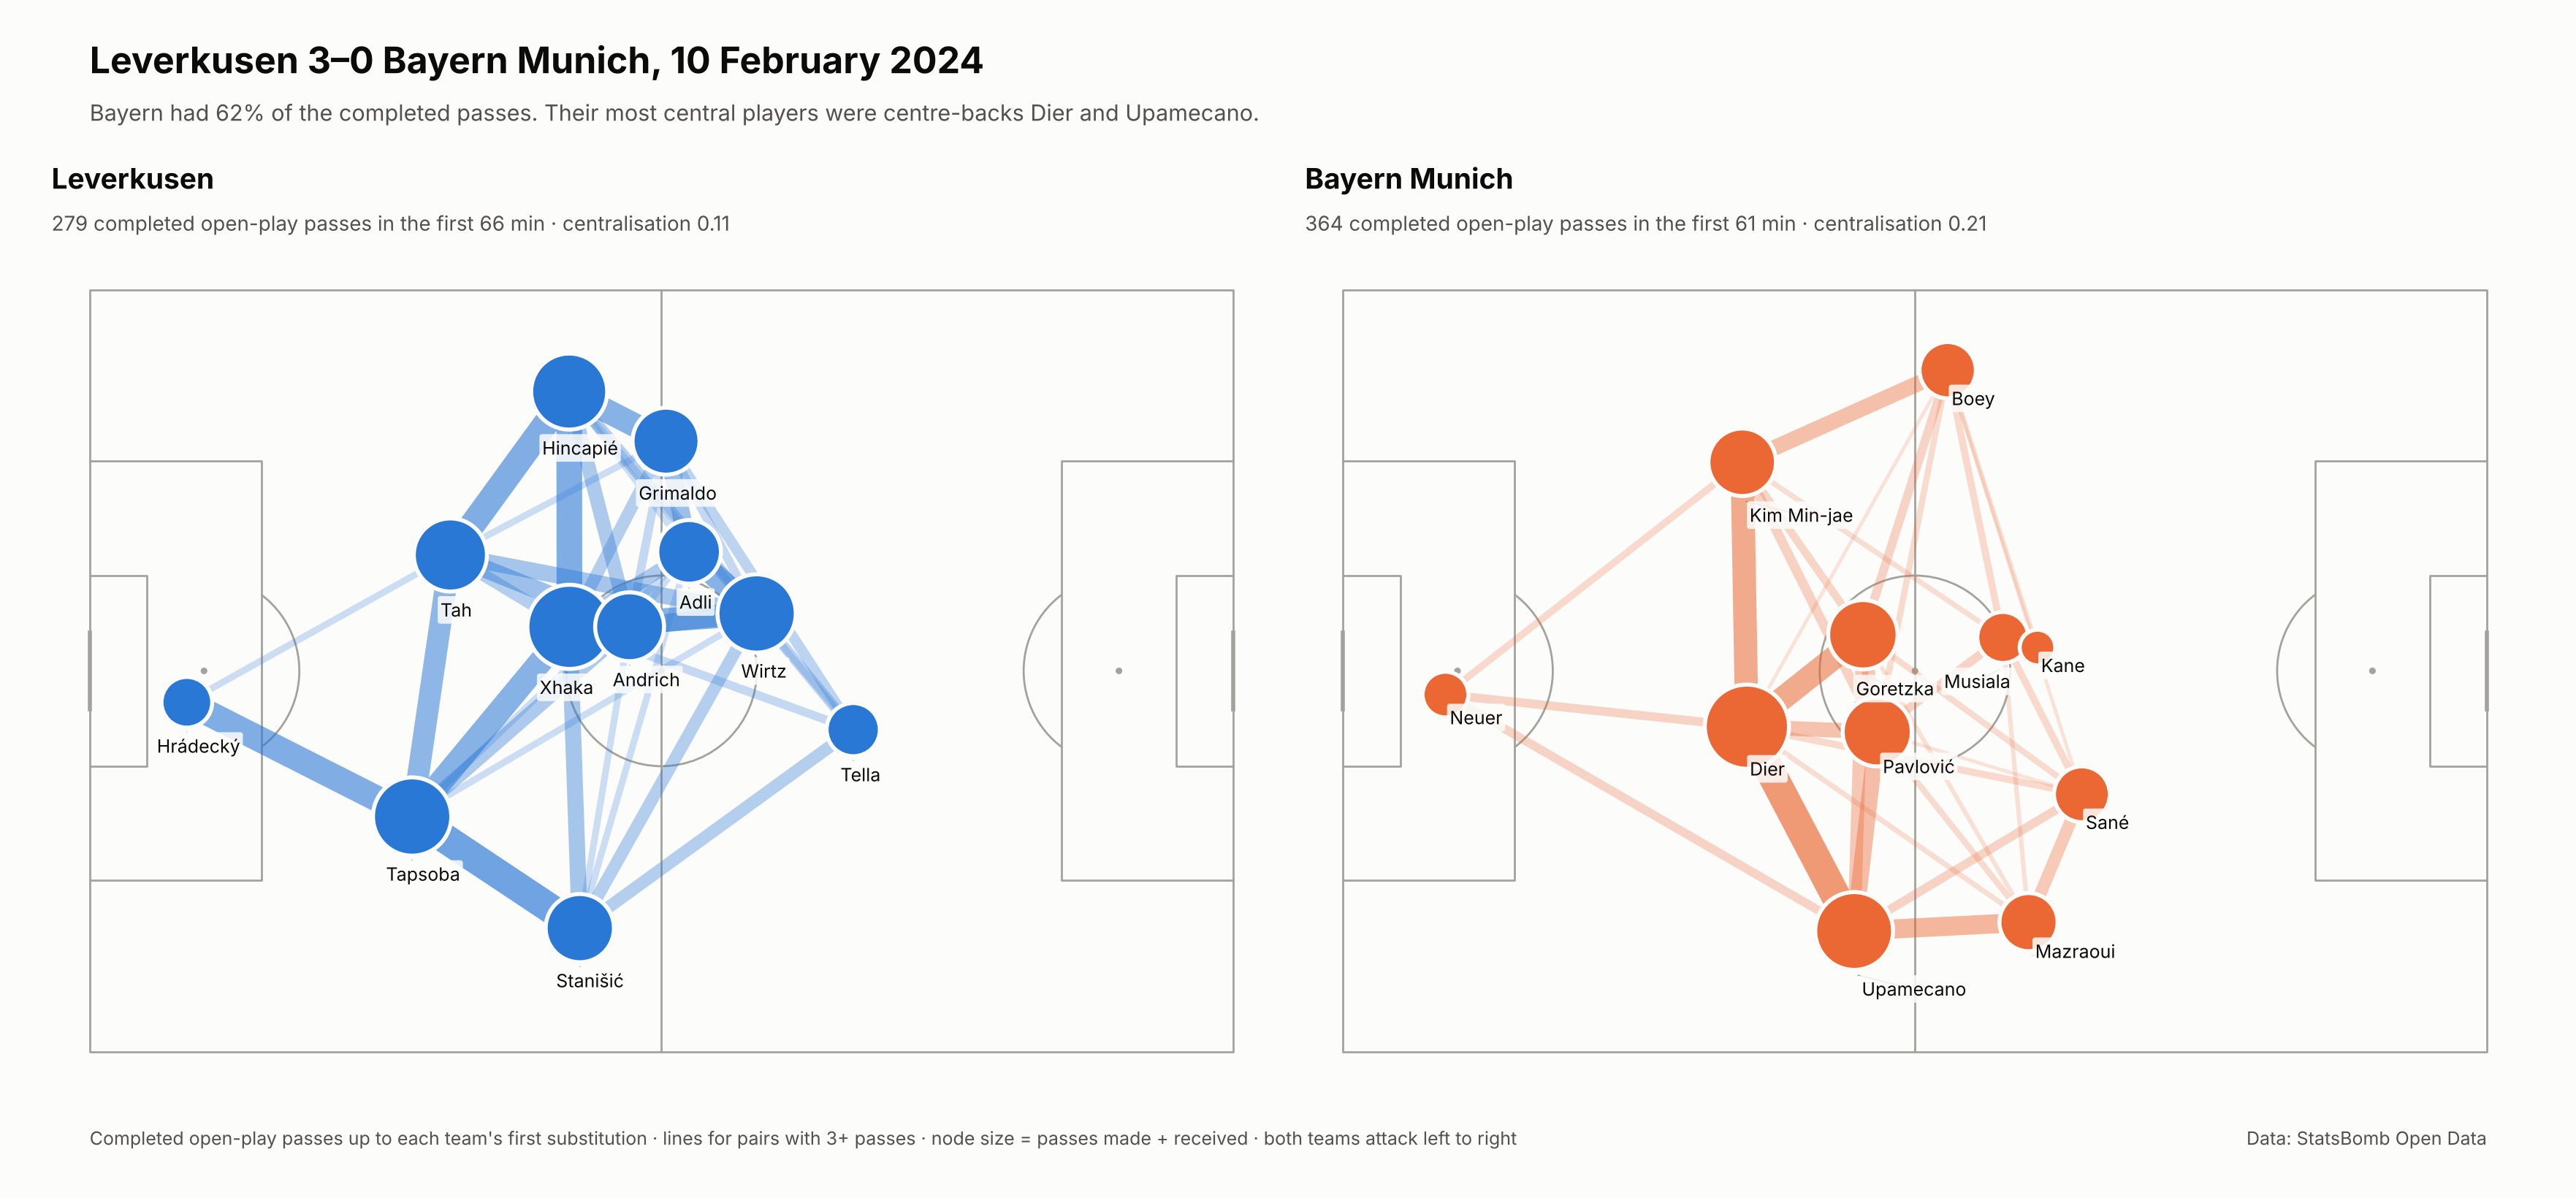

In [11]:
Image("../figures/leverkusen_bayern_3-0.png", width=900)

## 5. September vs February against Bayern

In [12]:
sep = db.match_id(TEAM, "Bayern Munich", "2023-09-15")
for label, m in [("Sep", sep), ("Feb", feb)]:
    n = db.run("04_match_nodes", match_id=m, team=TEAM, full_match=False)
    outfield = n[n["main_position"] != "Goalkeeper"]
    wirtz = n[n["player"] == "Florian Wirtz"].iloc[0]
    print(f"{label}: average outfield node x = {outfield['x'].mean():.1f} | "
          f"Wirtz: {wirtz['main_position']} at x = {wirtz['x']:.1f}")

Sep: average outfield node x = 60.8 | Wirtz: Left Wing at x = 62.8
Feb: average outfield node x = 55.4 | Wirtz: Center Forward at x = 70.0


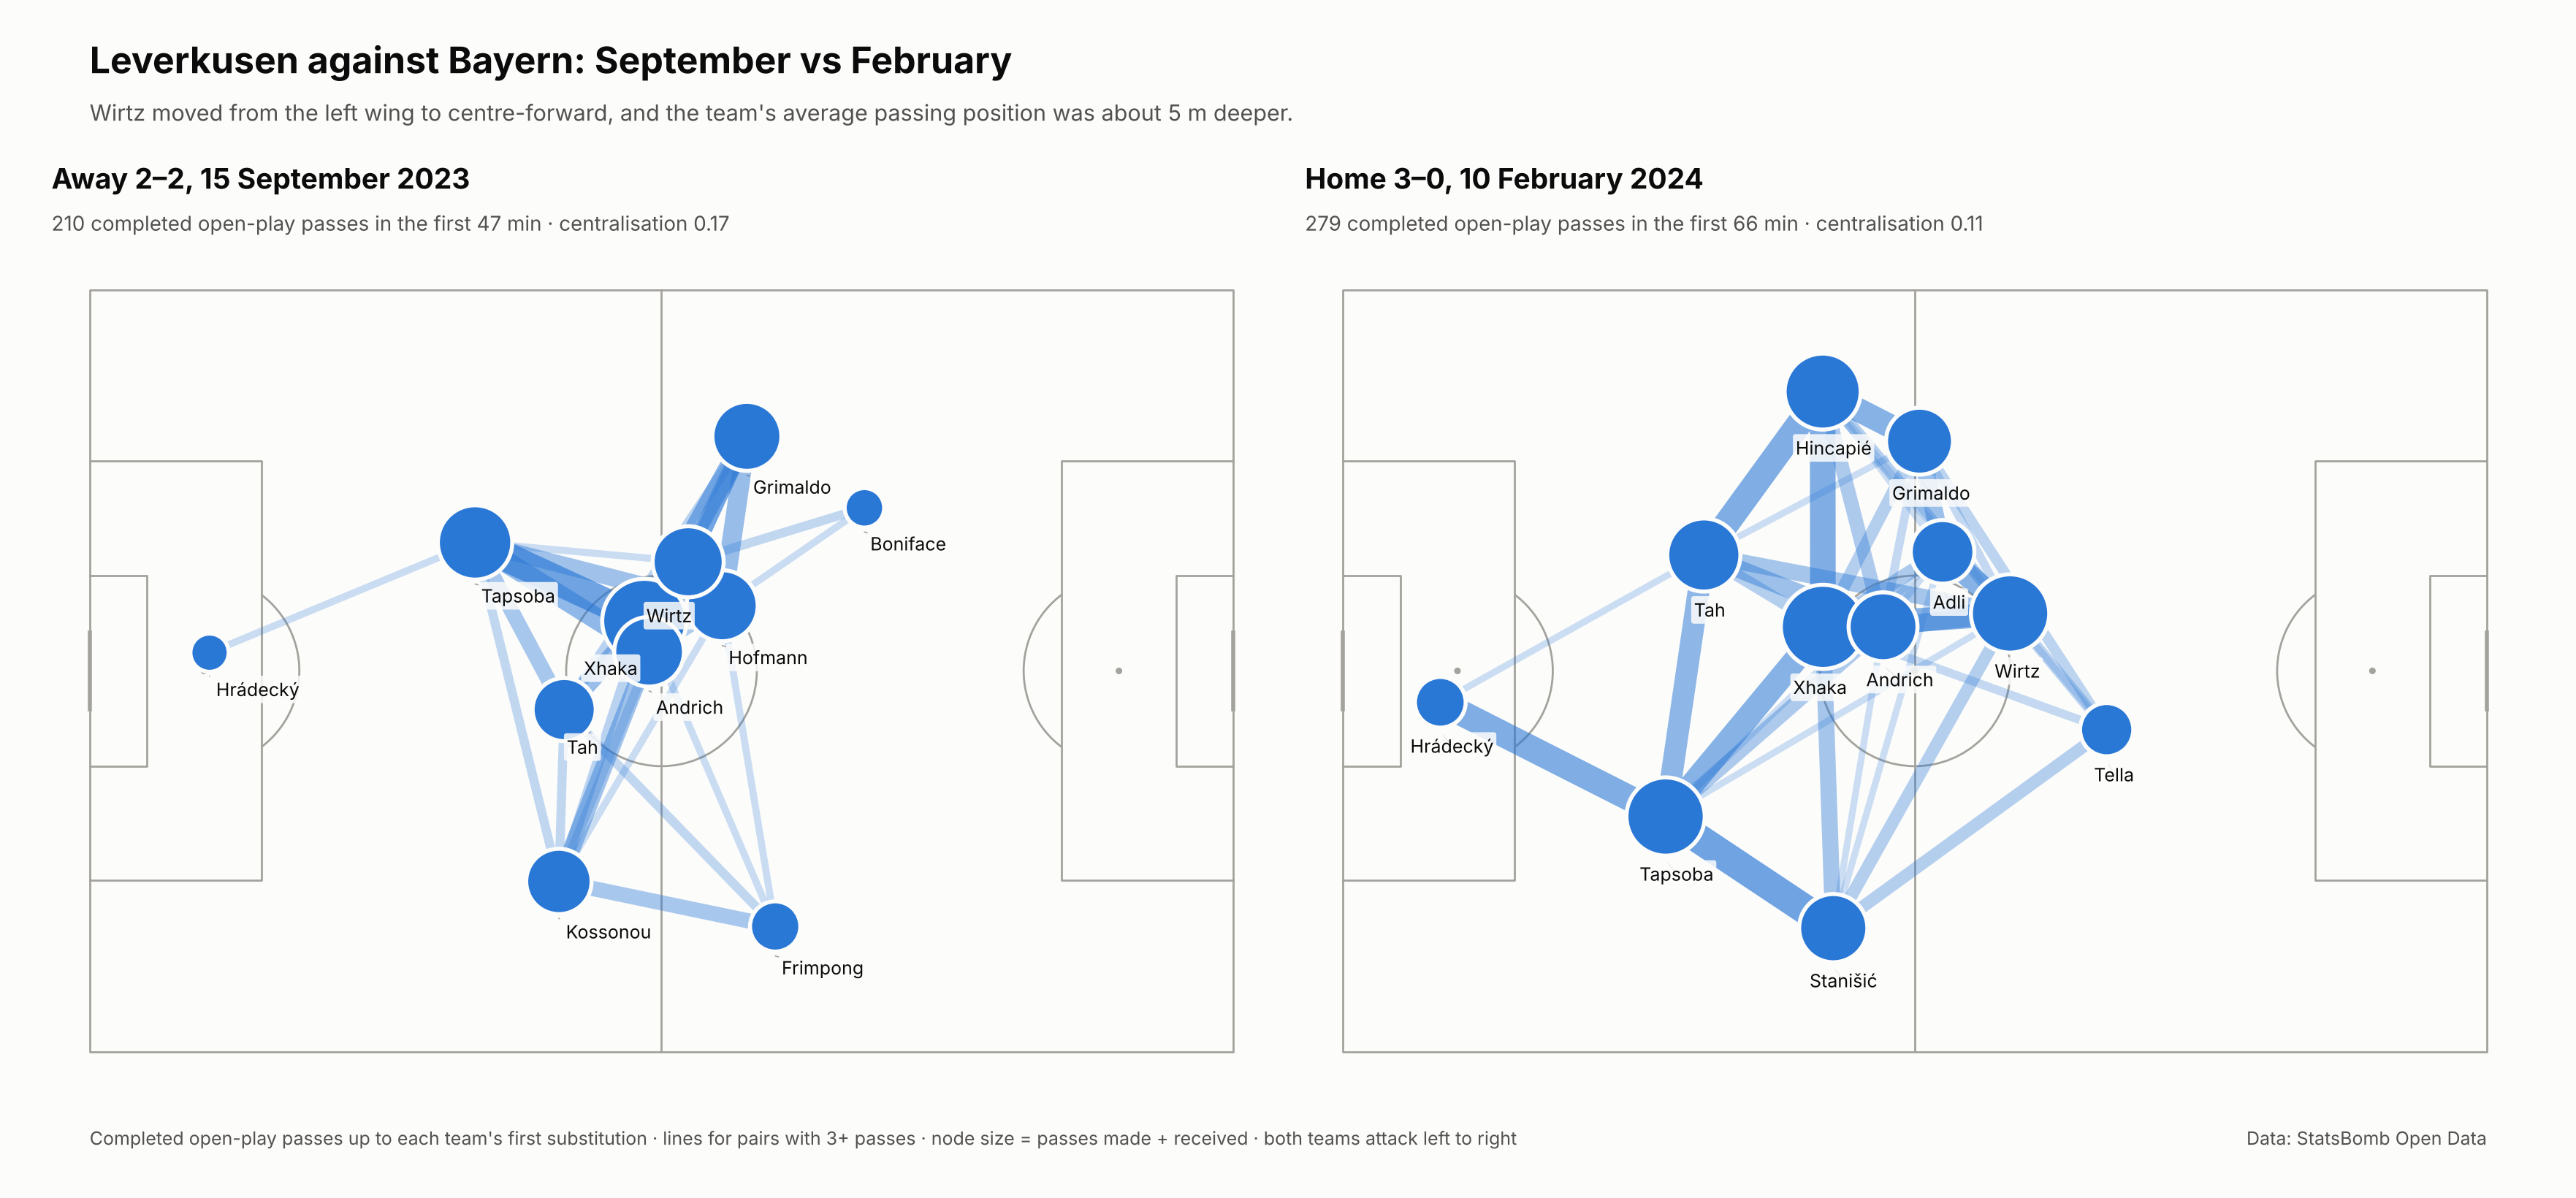

In [13]:
Image("../figures/leverkusen_vs_bayern_sep_vs_feb.png", width=900)

## Takeaways

- Xhaka was the hub: 28.9% of all completed open-play passes, and betweenness 0.53.
- Leverkusen usually dominated the ball (64%), but their best result against Bayern came with 37.7%.
- In that game Bayern's passing went through their centre-backs; Leverkusen's was spread across the team.
- Against Bayern in February, Wirtz moved to centre-forward and the team passed from about 5 m deeper.